# Shanghai T1DM / T2DM CGM dataset

Exploratory plots of the CSVs produced by `convert_shanghai.py` (run `uv run python analysis/convert_shanghai.py` first).

In [4]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

DATA = Path("../data/shanghai_csv")
patients = pd.read_csv(DATA / "patients.csv", parse_dates=["start_date"])
glucose = pd.read_csv(DATA / "glucose.csv", parse_dates=["timestamp"])
meals = pd.read_csv(DATA / "meals.csv", parse_dates=["timestamp"])
meds = pd.read_csv(DATA / "medications.csv", parse_dates=["timestamp"])

cohort = patients.set_index("recording_id")["diabetes_type"]
for df in (glucose, meals, meds):
    df["cohort"] = df["recording_id"].map(cohort)

COLORS = {"T1DM": "tab:red", "T2DM": "tab:blue"}
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

In [15]:
patients.groupby("diabetes_type").agg(
    recordings=("recording_id", "size"),
    patients=("patient_id", "nunique"),
    age=("age_years", "median"),
    bmi=("bmi_kg_m2", "median"),
    diabetes_years=("diabetes_duration_years", "median"),
    hba1c_mmol_mol=("hba1c_mmol_mol", "median"),
).round(1)

,recordings,patients,age,bmi,diabetes_years,hba1c_mmol_mol
diabetes_type,,,,,,
T1DM,16,12,58.5,20.9,8.5,69.4
T2DM,109,100,63.0,23.6,7.0,67.2


## Distribution of CGM readings
Dashed lines mark the 70–180 mg/dL target range.

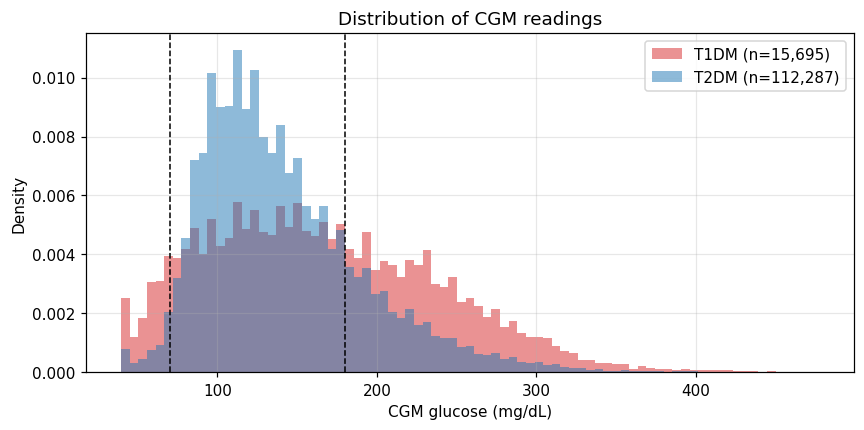

In [5]:
fig, ax = plt.subplots(figsize=(9, 4))
bins = np.arange(39.6, 480, 5.4)  # readings are mmol/L x 18, so bin widths must be multiples of 1.8
for name, g in glucose.groupby("cohort"):
    ax.hist(g["cgm_mg_dl"], bins=bins, density=True, alpha=0.5, color=COLORS[name], label=f"{name} (n={len(g):,})")
for x in (70, 180):
    ax.axvline(x, color="k", ls="--", lw=1)
ax.set(xlabel="CGM glucose (mg/dL)", ylabel="Density", title="Distribution of CGM readings")
ax.legend()
plt.show()

## Time in range per recording
Standard consensus bands: very low <54, low 54–69, in range 70–180, high 181–250, very high >250 mg/dL.

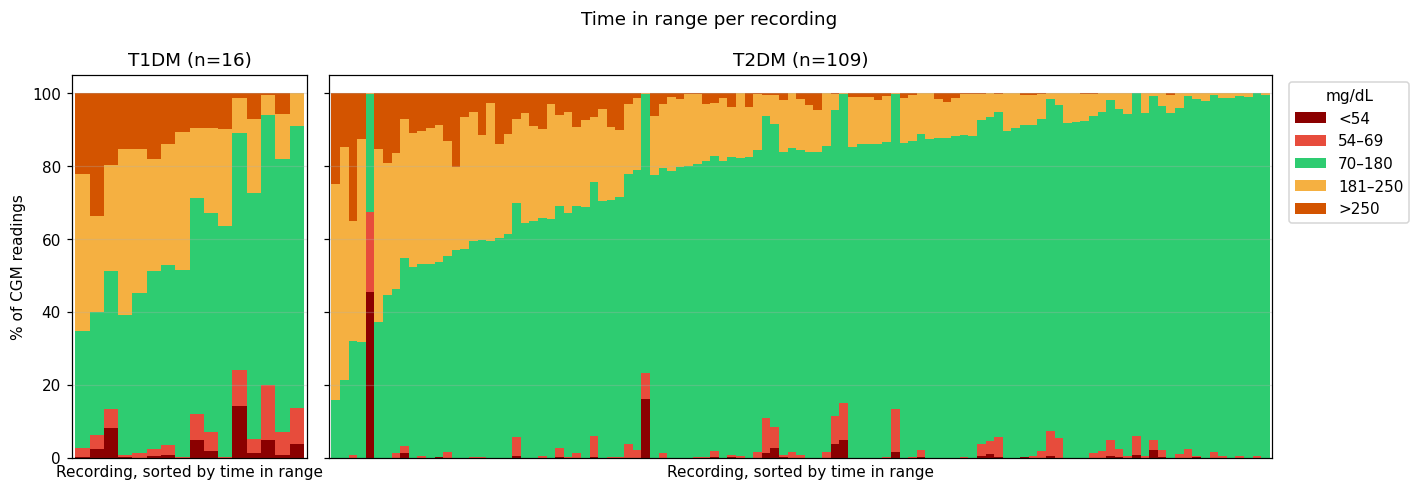

band,<54,54–69,70–180,181–250,>250
cohort,,,,,
T1DM,2.8,4.7,54.7,25.7,12.1
T2DM,0.8,1.6,77.7,16.0,3.9


In [6]:
BAND_LABELS = ["<54", "54–69", "70–180", "181–250", ">250"]
BAND_COLORS = ["#8b0000", "#e74c3c", "#2ecc71", "#f5b041", "#d35400"]
glucose["band"] = pd.cut(
    glucose["cgm_mg_dl"], [0, 54, 70, 180.5, 250.5, np.inf], labels=BAND_LABELS, right=False
)

tir = pd.crosstab(glucose["recording_id"], glucose["band"], normalize="index") * 100
tir.columns = tir.columns.astype(str)
tir = tir.reindex(columns=BAND_LABELS, fill_value=0)
tir["cohort"] = tir.index.map(cohort)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, gridspec_kw={"width_ratios": [1, 4]})
for ax, (name, g) in zip(axes, tir.groupby("cohort")):
    g.sort_values("70–180")[BAND_LABELS].plot.bar(stacked=True, ax=ax, color=BAND_COLORS, width=1, legend=False)
    ax.set(title=f"{name} (n={len(g)})", xlabel="Recording, sorted by time in range", xticks=[])
axes[0].set_ylabel("% of CGM readings")
axes[1].legend(title="mg/dL", bbox_to_anchor=(1.01, 1), loc="upper left")
fig.suptitle("Time in range per recording")
fig.tight_layout()
plt.show()

tir.groupby("cohort")[BAND_LABELS].mean().round(1)

## Ambulatory glucose profile
Median CGM by time of day (30-minute bins). Dark band is the interquartile range, light band the 10th–90th percentile.

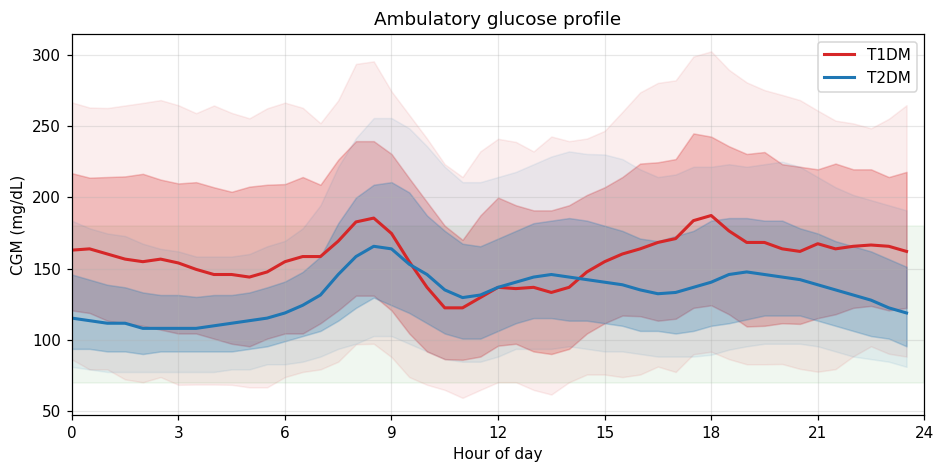

In [7]:
ts = glucose["timestamp"]
glucose["time_of_day"] = (ts.dt.hour * 60 + ts.dt.minute) // 30 * 0.5
profile = (
    glucose.groupby(["cohort", "time_of_day"])["cgm_mg_dl"]
    .quantile([0.1, 0.25, 0.5, 0.75, 0.9])
    .unstack()
)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.axhspan(70, 180, color="green", alpha=0.06)
for name, p in profile.groupby(level="cohort"):
    p = p.droplevel("cohort")
    ax.fill_between(p.index, p[0.1], p[0.9], color=COLORS[name], alpha=0.08)
    ax.fill_between(p.index, p[0.25], p[0.75], color=COLORS[name], alpha=0.25)
    ax.plot(p.index, p[0.5], color=COLORS[name], lw=2, label=name)
ax.set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="Hour of day", ylabel="CGM (mg/dL)",
       title="Ambulatory glucose profile")
ax.legend()
plt.show()

## Post-meal glucose response
CGM change relative to the reading at the logged meal time, for meals with a recorded description. Shaded bands are ±1 standard error.

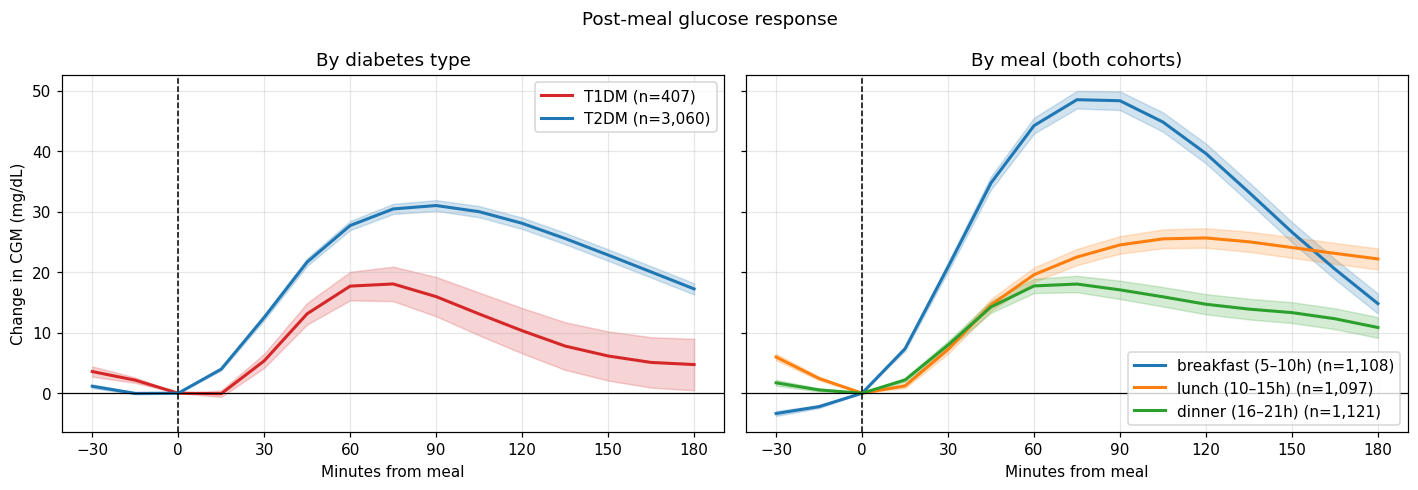

In [8]:
OFFSETS = range(-30, 181, 15)
cgm_lookup = glucose.set_index(["recording_id", "timestamp"])["cgm_mg_dl"]
recorded = meals[meals["description_recorded"]].copy()

curves = pd.DataFrame(
    {
        off: cgm_lookup.reindex(
            pd.MultiIndex.from_arrays([recorded["recording_id"], recorded["timestamp"] + pd.Timedelta(minutes=off)])
        ).to_numpy()
        for off in OFFSETS
    },
    index=recorded.index,
)
delta = curves.sub(curves[0], axis=0)

MEALS = ["breakfast (5–10h)", "lunch (10–15h)", "dinner (16–21h)"]
hour = recorded["timestamp"].dt.hour
recorded["meal"] = np.select([hour.between(5, 9), hour.between(10, 14), hour.between(16, 20)], MEALS, default="other")

def plot_mean_curve(ax, d, label, color=None):
    mean, sem = d.mean(), d.sem()
    line, = ax.plot(mean.index, mean, lw=2, color=color, label=f"{label} (n={len(d):,})")
    ax.fill_between(mean.index, mean - sem, mean + sem, color=line.get_color(), alpha=0.2)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for name, idx in recorded.groupby("cohort").groups.items():
    plot_mean_curve(axes[0], delta.loc[idx], name, COLORS[name])
axes[0].set_title("By diabetes type")
for name in MEALS:
    plot_mean_curve(axes[1], delta[recorded["meal"] == name], name)
axes[1].set_title("By meal (both cohorts)")
for ax in axes:
    ax.axvline(0, color="k", lw=1, ls="--")
    ax.axhline(0, color="k", lw=0.8)
    ax.set(xlabel="Minutes from meal", xticks=list(OFFSETS)[::2])
    ax.legend()
axes[0].set_ylabel("Change in CGM (mg/dL)")
fig.suptitle("Post-meal glucose response")
fig.tight_layout()
plt.show()

## Example recording
Three days of a T1DM recording with the most logged medication events: CGM, finger-stick checks, meals and insulin.

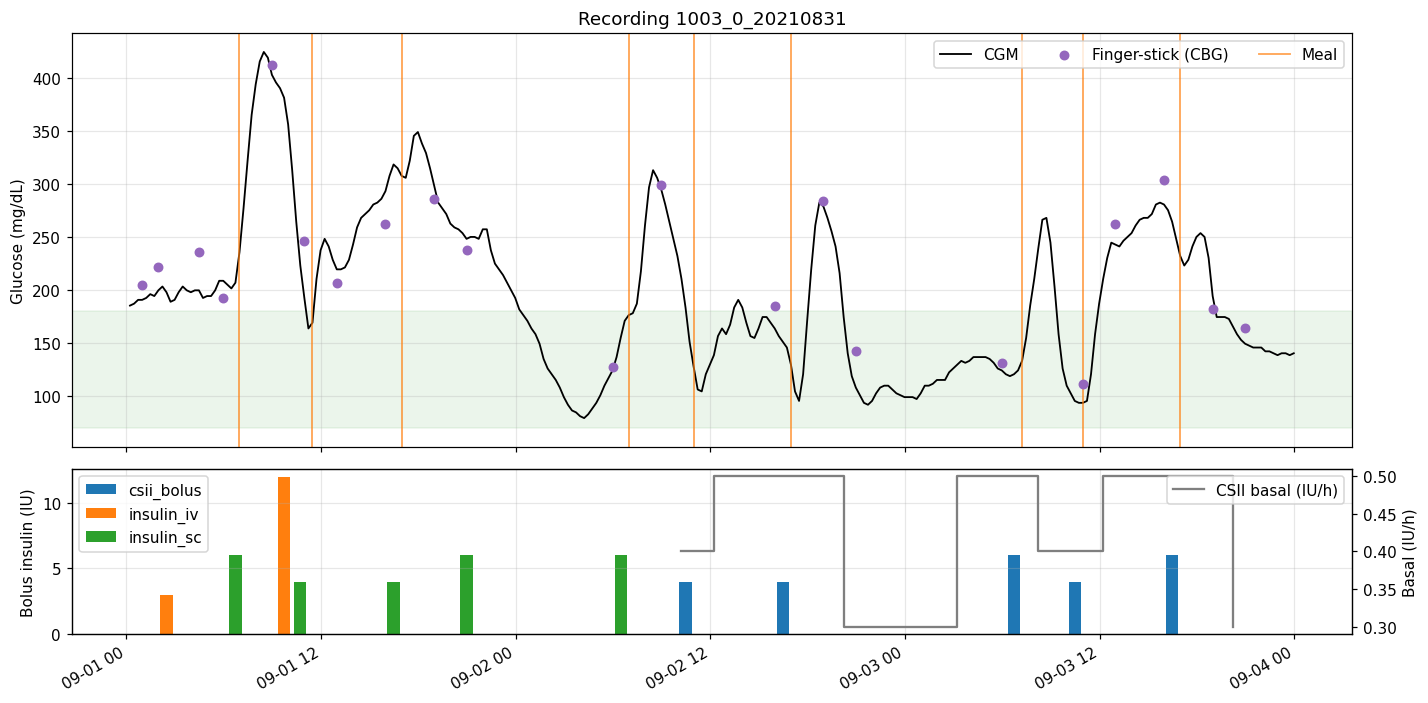

In [9]:
rid = meds.loc[meds["cohort"] == "T1DM", "recording_id"].value_counts().index[0]
start = glucose.loc[glucose["recording_id"] == rid, "timestamp"].min().normalize() + pd.Timedelta(days=1)
end = start + pd.Timedelta(days=3)

def window(df):
    return df[(df["recording_id"] == rid) & df["timestamp"].between(start, end, inclusive="left")]

g, m, md = window(glucose), window(meals), window(meds)
insulin = md[md["route"].isin(["insulin_sc", "csii_bolus", "insulin_iv"]) & md["dose"].notna()]
basal = md[(md["route"] == "csii_basal") & md["dose"].notna()]
oral = md[md["route"] == "oral"]

fig, (ax, ax2) = plt.subplots(2, 1, figsize=(13, 6.5), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
ax.axhspan(70, 180, color="green", alpha=0.08)
ax.plot(g["timestamp"], g["cgm_mg_dl"], color="k", lw=1.2, label="CGM")
ax.scatter(g["timestamp"], g["cbg_mg_dl"], color="tab:purple", s=30, zorder=3, label="Finger-stick (CBG)")
for i, t in enumerate(m["timestamp"]):
    ax.axvline(t, color="tab:orange", alpha=0.7, lw=1.2, label="Meal" if i == 0 else None)
if not oral.empty:
    ax.scatter(oral["timestamp"], np.full(len(oral), 50), marker="^", color="tab:brown", s=50, label="Oral agent")
ax.set(ylabel="Glucose (mg/dL)", title=f"Recording {rid}")
ax.legend(loc="upper right", ncol=4)

for route, d in insulin.groupby("route"):
    ax2.bar(d["timestamp"], d["dose"], width=pd.Timedelta(minutes=45), label=route)
ax2.set_ylabel("Bolus insulin (IU)")
if not basal.empty:
    ax2b = ax2.twinx()
    ax2b.step(basal["timestamp"], basal["dose"], where="post", color="tab:gray", label="CSII basal (IU/h)")
    ax2b.set_ylabel("Basal (IU/h)")
    ax2b.grid(False)
    ax2b.legend(loc="upper right")
ax2.legend(loc="upper left")
fig.autofmt_xdate()
fig.tight_layout()
plt.show()

## HbA1c vs mean CGM glucose
The dashed line is the ADAG estimated average glucose: eAG (mg/dL) = 28.7 × HbA1c(%) − 46.7.

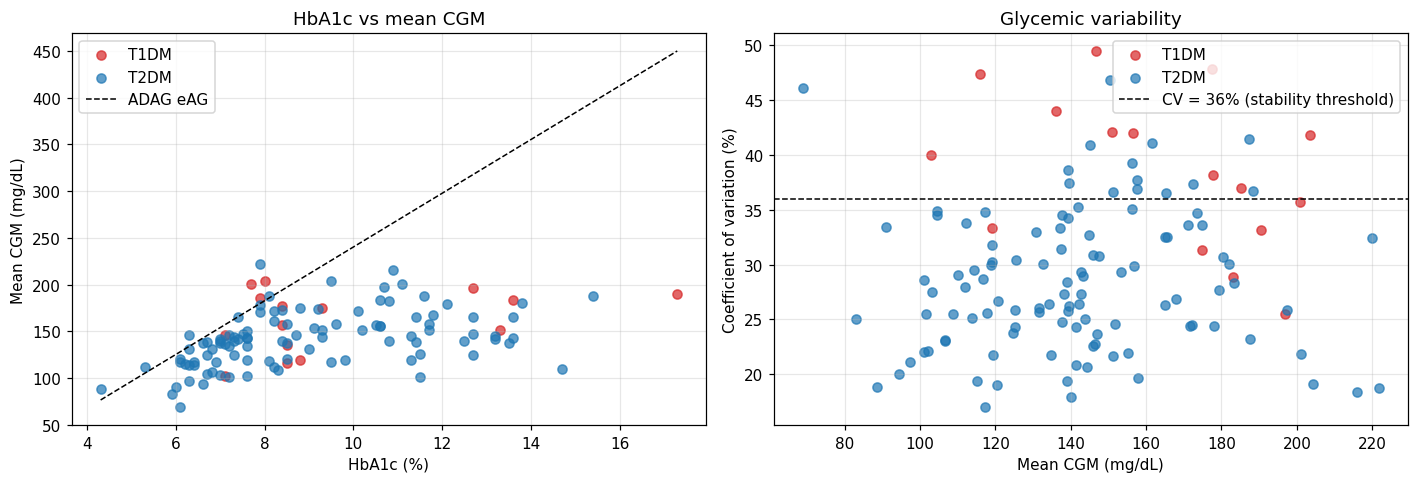

In [10]:
per_rec = glucose.groupby("recording_id")["cgm_mg_dl"].agg(mean_cgm="mean", cv=lambda s: s.std() / s.mean() * 100)
per_rec = per_rec.join(patients.set_index("recording_id")[["diabetes_type", "hba1c_mmol_mol"]])
per_rec["hba1c_pct"] = per_rec["hba1c_mmol_mol"] / 10.929 + 2.15

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for name, d in per_rec.groupby("diabetes_type"):
    axes[0].scatter(d["hba1c_pct"], d["mean_cgm"], color=COLORS[name], alpha=0.7, label=name)
    axes[1].scatter(d["mean_cgm"], d["cv"], color=COLORS[name], alpha=0.7, label=name)
a1c = np.linspace(per_rec["hba1c_pct"].min(), per_rec["hba1c_pct"].max(), 50)
axes[0].plot(a1c, 28.7 * a1c - 46.7, "k--", lw=1, label="ADAG eAG")
axes[0].set(xlabel="HbA1c (%)", ylabel="Mean CGM (mg/dL)", title="HbA1c vs mean CGM")
axes[1].axhline(36, color="k", ls="--", lw=1, label="CV = 36% (stability threshold)")
axes[1].set(xlabel="Mean CGM (mg/dL)", ylabel="Coefficient of variation (%)", title="Glycemic variability")
for ax in axes:
    ax.legend()
fig.tight_layout()
plt.show()

In [ ]:
import matplotlib.dates as mdates

patient_id = np.random.choice(patients["patient_id"].unique())
info = patients[patients["patient_id"] == patient_id].iloc[0]  # first recording if the patient has several
rid = info["recording_id"]

g = glucose[glucose["recording_id"] == rid]
m = meals[meals["recording_id"] == rid]
md = meds[meds["recording_id"] == rid]

MED_STYLE = {  # route: (label, color, y position of the marker row)
    "oral": ("Oral medication", "tab:brown", 22),
    "insulin_sc": ("Insulin injection", "tab:blue", 32),
    "csii_bolus": ("Insulin pump bolus", "tab:cyan", 32),
    "insulin_iv": ("IV insulin", "tab:purple", 32),
    "csii_basal": ("Insulin pump basal change", "tab:gray", 32),
}

fig, ax = plt.subplots(figsize=(14, 5))
ax.axhspan(70, 180, color="green", alpha=0.08, label="Target range (70–180)")
ax.plot(g["timestamp"], g["cgm_mg_dl"], color="k", lw=1, label="CGM glucose")
for i, t in enumerate(m["timestamp"]):
    ax.axvline(t, color="tab:orange", alpha=0.6, lw=1, label=f"Meal ({len(m)})" if i == 0 else None)
for route, d in md.groupby("route"):
    label, color, y = MED_STYLE[route]
    ax.scatter(d["timestamp"], np.full(len(d), y), marker="|", s=200, color=color, label=f"{label} ({len(d)})")

ax.set(
    ylim=(15, max(g["cgm_mg_dl"].max(), 200) + 20),
    ylabel="Glucose (mg/dL)",
    title=f"Patient {patient_id} ({info['diabetes_type']}, {info['gender']}, age {info['age_years']}) - recording {rid}",
)
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %d"))
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left")
fig.tight_layout()
plt.show()

## Updated CSV file

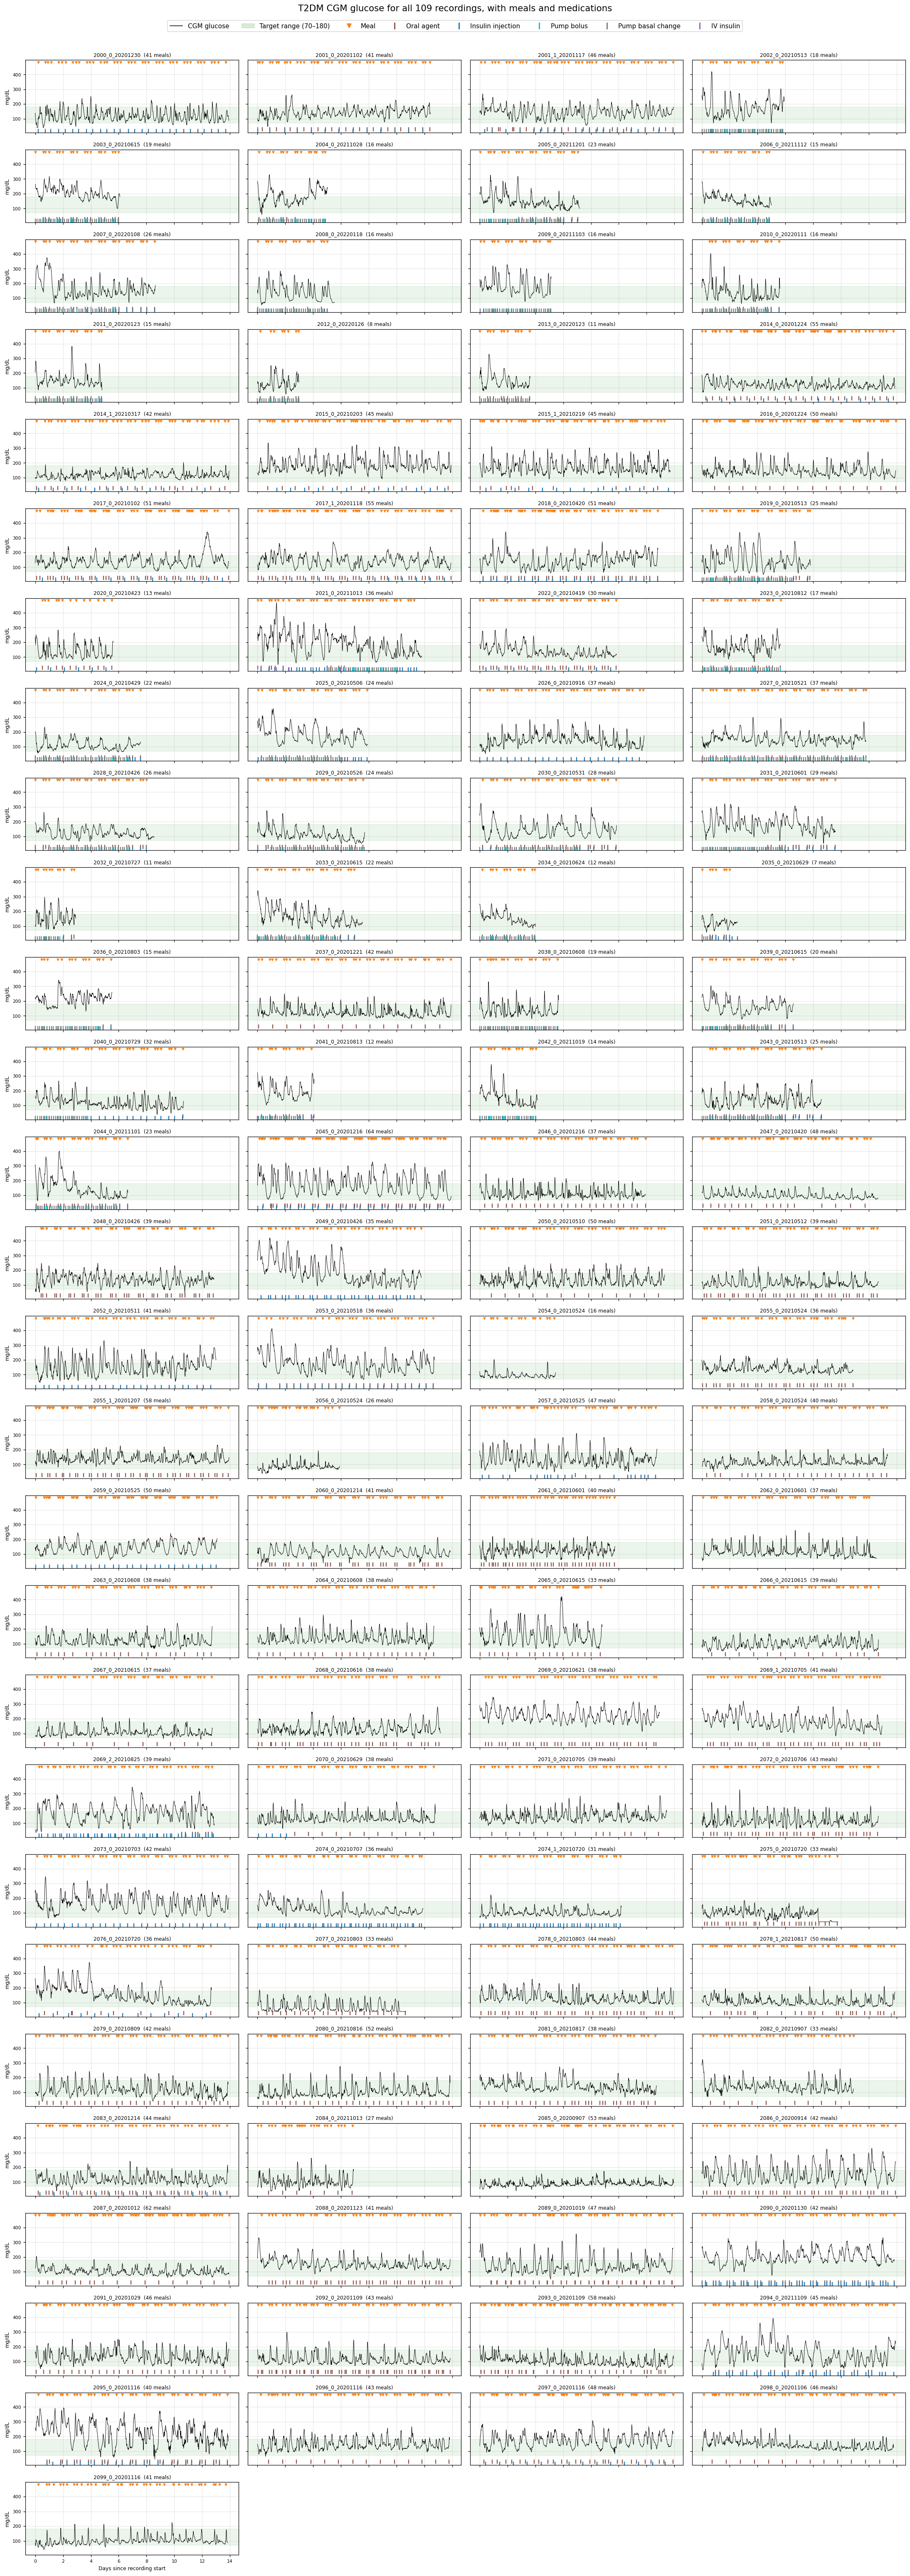

In [16]:
from matplotlib.lines import Line2D

raw = pd.read_csv(DATA / "Copy of T2DM_all_5min.xlsx - T2DM_5min.csv", parse_dates=["Date"], low_memory=False)

GLUCOSE_COL = "CGM (mg / dl)"
MEAL_COL = "Dietary intake"  # "data not available" still marks a logged meal time
MED_COLS = {  # column: (label, color, y position of the marker row)
    "Non-insulin hypoglycemic agents": ("Oral agent", "tab:brown", 28),
    "Insulin dose - s.c.": ("Insulin injection", "tab:blue", 16),
    "CSII - bolus insulin (Novolin R, IU)": ("Pump bolus", "tab:cyan", 16),
    "CSII - basal insulin (Novolin R, IU / H)": ("Pump basal change", "tab:gray", 16),
    "Insulin dose - i.v.": ("IV insulin", "tab:purple", 16),
}
MEAL_Y = raw[GLUCOSE_COL].max() + 15

recordings = raw.groupby("Recording", sort=False)
ncols = 4
nrows = -(-recordings.ngroups // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 2 * nrows), sharex=True, sharey=True)

for ax, (rid, r) in zip(axes.flat, recordings):
    days = (r["Date"] - r["Date"].iloc[0]) / pd.Timedelta(days=1)
    ax.axhspan(70, 180, color="green", alpha=0.08)
    ax.plot(days, r[GLUCOSE_COL], color="k", lw=0.6)
    meal = r[MEAL_COL].notna()
    ax.scatter(days[meal], np.full(meal.sum(), MEAL_Y), marker="v", s=10, color="tab:orange")
    for col, (_, color, y) in MED_COLS.items():
        on = r[col].notna()
        ax.scatter(days[on], np.full(on.sum(), y), marker="|", s=40, color=color)
    ax.set_title(f"{rid}  ({meal.sum()} meals)", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes.flat[recordings.ngroups:]:
    ax.axis("off")
for ax in axes[:, 0]:
    ax.set_ylabel("mg/dL", fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Days since recording start", fontsize=8)
axes[0, 0].set_ylim(5, MEAL_Y + 15)

handles = [
    Line2D([], [], color="k", lw=1, label="CGM glucose"),
    plt.Rectangle((0, 0), 1, 1, color="green", alpha=0.15, label="Target range (70–180)"),
    Line2D([], [], marker="v", color="tab:orange", ls="", label="Meal"),
] + [
    Line2D([], [], marker="|", color=color, ls="", markersize=10, mew=2, label=label)
    for label, color, _ in MED_COLS.values()
]
fig.legend(handles=handles, loc="upper center", ncol=len(handles), bbox_to_anchor=(0.5, 1.0), fontsize=10)
fig.suptitle(f"T2DM CGM glucose for all {recordings.ngroups} recordings, with meals and medications", y=1.005, fontsize=14)
fig.tight_layout(rect=(0, 0, 1, 0.995))
plt.show()

## Get the macros from the food


In [17]:
raw = pd.read_csv(DATA / "Copy of T2DM_all_5min.xlsx - T2DM_5min.csv", parse_dates=["Date"], low_memory=False)

2790
